# 01 · What it costs to serve a time series foundation model

**Block 6 · W44, notebook 1 of 1.** Mistral's Timestral family runs on CPU, with published latencies. That turns a
modelling question ("which size is best?") into a serving question: what does each size cost to run on a park of
series, and when is the bigger model worth it?

| § | Question | Short answer |
|---|---|---|
| 1 | What do we actually know about each size? | Two latencies published, two derived, one 0.2% score gap. |
| 2 | What does the CPU cost per month? | Very little: 163 EUR for a daily refresh of 500,000 series with 209M. |
| 3 | So what do we pay for? | Peak capacity: the workers needed to finish inside a nightly window, x48 the CPU consumed. |
| 4 | When does 209M repay its extra CPU over 123M? | Above 0.16 EUR of decision loss per series per month, *if* 0.2% of benchmark score is 0.2% of decision loss. |
| 5 | And against a classic model? | Measured at 0.0016 ms per series: compute is not the argument, accuracy and licence are. |
| 6 | Can we use the weights at all? | Depends on the client's revenue: Modified MIT has a 20M USD per month cap. |

> **How to read this notebook.** Callouts follow a fixed code:
> **Intuition**, the idea without equations · **Example**, a worked number ·
> **Watch out**, the trap to avoid · **Takeaway**, the memo to keep.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display


from w44_retraining import serving, viz

viz.setup()
export = viz.exporter("../figures")


def show(headers, rows):
    """Render a small table as Markdown (no pandas dependency)."""
    lines = ["| " + " | ".join(map(str, headers)) + " |", "|" + "---|" * len(headers)]
    lines += ["| " + " | ".join(map(str, r)) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

## 1. The inputs, and how each one is known

Every downstream number is only as good as these four rows. The announcement gives two latencies (5M and 209M) and
two ratios ("28M is five times faster than 209M", "123M reaches 0.2% of the 209M score at three quarters of its
latency"). The workload behind those latencies is specific: **one day ahead from three weeks of 15-minute
history**, i.e. a 2,016-step context and a 96-step horizon, on a server CPU with 8 threads.

In [2]:
show(["model", "parameters (M)", "latency ms, 8 threads", "fp32 weights MB", "latency source"],
     [(nm, p, lat, mb, src) for nm, (p, lat, mb, src) in serving.MODELS.items()])
print(f"declared CPU price: {serving.PRICE_VCPU_H} EUR per vCPU-hour | published score gap 123M vs 209M: "
      f"{serving.PUBLISHED_SCORE_GAP_123_209:.1%}")

| model | parameters (M) | latency ms, 8 threads | fp32 weights MB | latency source |
|---|---|---|---|---|
| Timestral-5M | 5 | 10.0 | 21 | published |
| Timestral-28M | 28 | 28.0 | 111 | derived: 140 / 5 |
| Timestral-123M | 123 | 105.0 | 490 | derived: 140 x 3/4 |
| Timestral-209M | 209 | 140.0 | 837 | published |

declared CPU price: 0.035 EUR per vCPU-hour | published score gap 123M vs 209M: 0.2%


> **Watch out.** Two of the four latencies are arithmetic on a sentence, not measurements, and none of them was
> measured on an hourly park with a 24-step horizon. Everything below holds *for the published workload*. On a
> client park, the first thing to do is to time one batch.

## 2. What the CPU costs: almost nothing

**Question.** If we only pay for the CPU-seconds we use, how much is a month of forecasts?

The model: a park of $S$ series refreshed every $k$ hours makes $S \cdot 720 / k$ inferences a month. Each one
holds 8 threads for its latency (no batching, which is pessimistic). CPU-hours times price gives euros.

In [3]:
cost = serving.study()
show(["park", "model", "every 1 h", "every 6 h", "every 24 h", "every 168 h"],
     [(f"{S:,}", nm, *(f"{v:,.0f}" for v in row.values())) for S, tab in cost["cost"].items()
      for nm, row in tab.items()])

| park | model | every 1 h | every 6 h | every 24 h | every 168 h |
|---|---|---|---|---|---|
| 1,000 | Timestral-5M | 1 | 0 | 0 | 0 |
| 1,000 | Timestral-28M | 2 | 0 | 0 | 0 |
| 1,000 | Timestral-123M | 6 | 1 | 0 | 0 |
| 1,000 | Timestral-209M | 8 | 1 | 0 | 0 |
| 20,000 | Timestral-5M | 11 | 2 | 0 | 0 |
| 20,000 | Timestral-28M | 31 | 5 | 1 | 0 |
| 20,000 | Timestral-123M | 118 | 20 | 5 | 1 |
| 20,000 | Timestral-209M | 157 | 26 | 7 | 1 |
| 500,000 | Timestral-5M | 280 | 47 | 12 | 2 |
| 500,000 | Timestral-28M | 784 | 131 | 33 | 5 |
| 500,000 | Timestral-123M | 2,940 | 490 | 123 | 18 |
| 500,000 | Timestral-209M | 3,920 | 653 | 163 | 23 |

> **Example.** 500,000 series, refreshed every hour, with the largest model: 360 million inferences of 140 ms on 8
> threads, i.e. 112,000 vCPU-hours, 3,920 EUR a month. Refreshed daily: 163 EUR. For a forecasting team, that is
> a rounding error.

## 3. What we really pay for: capacity sized for a window

**Question.** If CPU is cheap, why does model size matter?

> **Intuition.** Forecasts are usually produced in a batch window: the warehouse closes at night, and every series
> must be refreshed before the business opens. The question is not "how many CPU-seconds", it is "how many
> workers must exist **at the same time** to finish in 30 minutes". Unless the platform scales to zero between
> windows, those workers are paid all month.

A worker (8 vCPU) serves $1000 / \text{latency}$ inferences per second; the window needs $S / (60 \cdot
\text{minutes})$ per second.

In [4]:
keys = list(cost["window"])
show(["model"] + [f"{S:,} series, {win} min" for S, win in keys],
     [(nm, *(f"{cost['window'][key][nm]} workers ({cost['provisioned'][key][nm]:,.0f} EUR)" for key in keys))
      for nm in serving.MODELS])

| model | 20,000 series, 30 min | 500,000 series, 30 min | 500,000 series, 120 min |
|---|---|---|---|
| Timestral-5M | 1 workers (202 EUR) | 3 workers (605 EUR) | 1 workers (202 EUR) |
| Timestral-28M | 1 workers (202 EUR) | 8 workers (1,613 EUR) | 2 workers (403 EUR) |
| Timestral-123M | 2 workers (403 EUR) | 30 workers (6,048 EUR) | 8 workers (1,613 EUR) |
| Timestral-209M | 2 workers (403 EUR) | 39 workers (7,862 EUR) | 10 workers (2,016 EUR) |

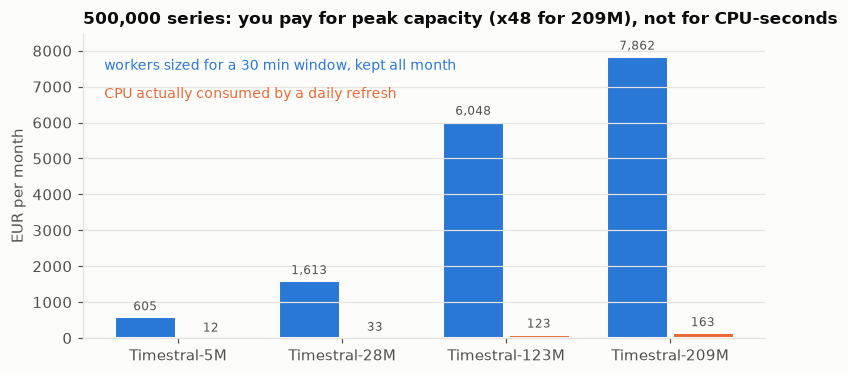

ratio provisioned / consumed: {'5M': 51.8, '28M': 49.4, '123M': 49.4, '209M': 48.1}


In [5]:
sizes = [nm.split("-")[1] for nm in serving.MODELS]
prov = [cost["provisioned"][500_000, 30][nm] for nm in serving.MODELS]
used = [cost["consumed_daily_500k"][nm] for nm in serving.MODELS]
x = np.arange(len(sizes))
fig, ax = plt.subplots(figsize=(8, 3.6))
b1 = ax.bar(x - 0.2, prov, width=0.38, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=2)
b2 = ax.bar(x + 0.2, used, width=0.38, color=viz.ORANGE, edgecolor=viz.SURFACE, linewidth=2)
ax.bar_label(b1, labels=[f"{v:,.0f}" for v in prov], padding=2, color=viz.TEXT_2, fontsize=8)
ax.bar_label(b2, labels=[f"{v:,.0f}" for v in used], padding=2, color=viz.TEXT_2, fontsize=8)
ax.grid(axis="x", visible=False)
ax.set_xticks(x, [f"Timestral-{s}" for s in sizes])
ax.set_ylabel("EUR per month")
ax.text(-0.45, prov[-1] * 0.95, "workers sized for a 30 min window, kept all month", color=viz.BLUE, fontsize=9)
ax.text(-0.45, prov[-1] * 0.85, "CPU actually consumed by a daily refresh", color=viz.ORANGE, fontsize=9)
ax.set_ylim(0, prov[-1] * 1.08)
ax.set_title("500,000 series: you pay for peak capacity (x48 for 209M), not for CPU-seconds")
export(fig, "provisioned_vs_consumed"); plt.show()
print("ratio provisioned / consumed:", {s: round(p / u, 1) for s, p, u in zip(sizes, prov, used, strict=True)})

> **Takeaway.** 209M needs 39 workers for a 30-minute window on 500,000 series, 123M needs 30 (+30%), 5M needs 3
> (13 times fewer). Kept all month, those 39 workers cost 7,862 EUR, against 163 EUR of CPU actually used by a
> daily refresh. **Model size is paid in provisioned capacity.** Widening the window to 120 minutes divides the
> fleet by about four, which is often a cheaper lever than a smaller model.

## 4. When is the bigger model worth it?

**Question.** 209M costs 33% more CPU than 123M for a 0.2% better benchmark score. At what stakes does that pay?

Write $L$ for the **decision loss** per series per month (what forecast error costs the business: stock-outs,
overstock, imbalance penalties). If the bigger model reduces $L$ by a relative $\delta$, it saves $\delta \cdot L$
per series. It pays when that exceeds its extra CPU per series:

$$\delta^\ast = \frac{\text{cost}_{209M} - \text{cost}_{123M}}{S \cdot L}.$$

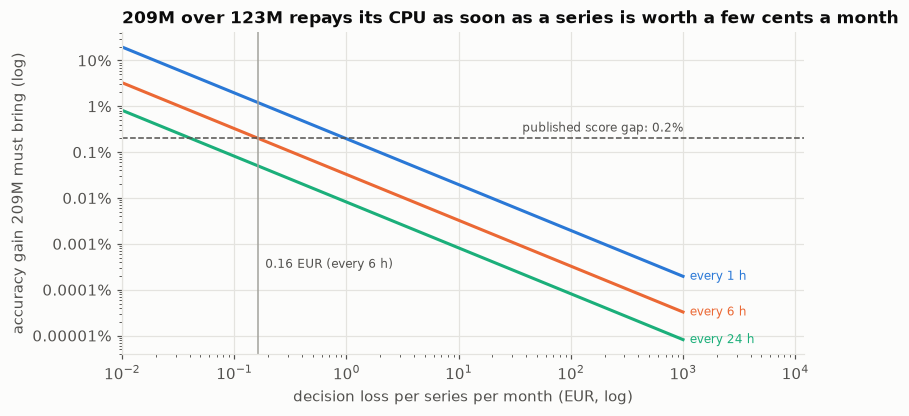

threshold at k = 6 h: 0.16 EUR per series per month


In [6]:
L = np.logspace(-2, 3, 200)
fig, ax = plt.subplots(figsize=(8, 3.8))
colors = {1: viz.BLUE, 6: viz.ORANGE, 24: viz.AQUA}
for k, c in colors.items():
    d = [serving.breakeven_gain(20_000, k, 140.0, 105.0, l_) for l_ in L]
    ax.plot(L, d, color=c)
    ax.text(L[-1] * 1.15, d[-1], f"every {k} h", color=c, fontsize=8, va="center")
ax.axhline(serving.PUBLISHED_SCORE_GAP_123_209, color=viz.TEXT_2, ls="--", lw=1)
ax.text(L[-1], serving.PUBLISHED_SCORE_GAP_123_209 * 1.4, "published score gap: 0.2%", ha="right",
        color=viz.TEXT_2, fontsize=8)
ax.axvline(cost["breakeven_threshold"], color=viz.MUTED, lw=1)
ax.text(cost["breakeven_threshold"] * 1.15, 3e-6, f"{cost['breakeven_threshold']:.2f} EUR (every 6 h)",
        color=viz.TEXT_2, fontsize=8)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("decision loss per series per month (EUR, log)")
ax.set_ylabel("accuracy gain 209M must bring (log)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{100 * v:.6f}".rstrip("0").rstrip(".") + "%"))
ax.set_xlim(L[0], L[-1] * 12)
ax.set_title("209M over 123M repays its CPU as soon as a series is worth a few cents a month")
export(fig, "breakeven_209m_vs_123m"); plt.show()
print(f"threshold at k = 6 h: {cost['breakeven_threshold']:.2f} EUR per series per month")

> **Watch out.** The 0.2% is a gap in an aggregate **benchmark score**, not a 0.2% reduction of *your* decision
> loss. The threshold of 0.16 EUR holds only under that equivalence. On a client's data the gap between the two
> sizes has to be measured, and it can be larger, smaller, or of the opposite sign.

## 5. Against a classic model, measured

**Question.** The block 2 model (a window mean plus a daily profile) is the baseline every TSFM has to beat. What
does it cost? The plan *declared* 0.08 ms; here it is timed (one refit plus one forecast for 2,000 series,
vectorised numpy, best of 5).

In [7]:
print(f"measured in this run: {cost['classic_ms']:.4f} ms per series (it varies run to run on a shared machine; "
      "the README quotes 0.0016 ms)")
show(["decision loss EUR/series/month", "28M must beat it by", "209M must beat it by"],
     [(f"{c:.2f}", f"{r['Timestral-28M']:.2%}", f"{r['Timestral-209M']:.2%}")
      for c, r in cost["classic_breakeven"].items()])

measured in this run: 0.0011 ms per series (it varies run to run on a shared machine; the README quotes 0.0016 ms)


| decision loss EUR/series/month | 28M must beat it by | 209M must beat it by |
|---|---|---|
| 0.10 | 0.26% | 1.31% |
| 1.00 | 0.03% | 0.13% |
| 10.00 | 0.00% | 0.01% |

> **Takeaway.** Even against a model that is close to free (about a thousandth of a millisecond per series,
> five orders of magnitude below 209M), a TSFM only needs to cut the decision loss by 0.03%
> (28M) to 0.13% (209M) at 1 EUR per series per month to repay its CPU. **Compute is not the argument against a
> foundation model. Accuracy on your data and the weights licence are.** (The timing varies a little between
> runs; it changes no conclusion.)

## 6. Can we use the weights? The licence, read at the source

The GitHub repository shows an Apache-2.0 badge: it describes the **code**. The weights live on the Hugging Face
Hub under a separate `LICENSE` file titled "Modified MIT License". It is MIT-like, with one decisive clause:

> 2. You are not authorized to exercise any rights under this license if the global consolidated monthly revenue
> of your company (or that of your employer) exceeds $20 million [...] for the preceding month. This restriction
> [...] applies to the Model and any derivatives, modifications, or combined works based on it [...]

So the licence is a **function of the client**, and the gate must be too.

In [8]:
revenues = [None, 1e6, 19e6, 21e6, 300e6]
fams = ("Timestral", "Chronos-2", "TimesFM-3")
show(["client revenue", *fams],
     [("unknown" if r is None else f"{r / 1e6:.0f}M USD/month", *(serving.licence_gate(f, r) for f in fams))
      for r in revenues])

| client revenue | Timestral | Chronos-2 | TimesFM-3 |
|---|---|---|---|
| unknown | REFUSE: client revenue unknown, licence has a revenue cap | ALLOW (apache-2.0) | REFUSE: weights licence not read at the source |
| 1M USD/month | ALLOW under the cap (Modified MIT), re-check monthly; derivatives inherit the cap | ALLOW (apache-2.0) | REFUSE: weights licence not read at the source |
| 19M USD/month | ALLOW under the cap (Modified MIT), re-check monthly; derivatives inherit the cap | ALLOW (apache-2.0) | REFUSE: weights licence not read at the source |
| 21M USD/month | REFUSE: revenue above the 20M USD/month cap | ALLOW (apache-2.0) | REFUSE: weights licence not read at the source |
| 300M USD/month | REFUSE: revenue above the 20M USD/month cap | ALLOW (apache-2.0) | REFUSE: weights licence not read at the source |

> **Intuition.** "Modified MIT" reads like "MIT". It is not: above about 240M USD of annual revenue the user has
> no rights at all, fine-tunes included, and the test looks at the *employer* too. For a consultant, that is the
> client's revenue, and it must be re-checked every month.

> **Takeaway.** Read the weights licence where the weights are, not on the code repository. Chronos-2 is the
> counter-example: Apache-2.0 for code *and* weights, so it is the open option for clients above the cap.

**What to keep from this block.**
1. CPU-seconds are cheap; peak capacity for a batch window is what you pay (x48 for 209M at 500,000 series).
2. A bigger size repays its CPU at a few cents of decision loss per series per month, *if* the benchmark gap
   transfers to your data. That transfer is the thing to measure.
3. The licence gate takes the client's revenue as an input.